In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [3]:
df=pd.read_csv('diabetes_patients_10000_full.csv')
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [4]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Sugar_Level', 'Creatinine', 'BMI',
       'Urea', 'Cholesterol', 'HbA1c', 'Class'],
      dtype='object')

In [5]:
df.shape

(10000, 10)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   object 
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB


In [7]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,10000.00000,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,5000.50000,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,2886.89568,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,1.00000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2500.75000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5000.50000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7500.25000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.00000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [8]:
df.isna().sum()

Patient_ID            0
Age                  14
Gender               40
Blood_Sugar_Level    53
Creatinine           56
BMI                  51
Urea                 51
Cholesterol          32
HbA1c                 0
Class                 0
dtype: int64

In [9]:
df.drop(columns=['Patient_ID'],axis=1,inplace=True)

In [10]:
df.dropna(subset=['Age','Gender','Blood_Sugar_Level','Creatinine','BMI','Urea','Cholesterol'],inplace=True)
df.reset_index(drop=True,inplace=True)


In [11]:
df.select_dtypes(include=['object']).nunique()

Gender    2
Class     2
dtype: int64

In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])
df['Class'] = le.fit_transform(df['Class'])



In [13]:
X=df.drop('Class', axis=1)
y=df['Class']

In [14]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (7945, 8)  y_train =  (7945,)
X_test  =  (1987, 8)  y_test  =  (1987,)


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [16]:
results=[]
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
model_lr = LogisticRegression(class_weight='balanced',max_iter=1000)
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

results.append({
    'Method': "Class Weight Balanced LogisticRegression",
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr),
    'Recall': recall_score(y_test, y_pred_lr),
    'F1-Score': f1_score(y_test, y_pred_lr)
})

In [17]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

for name, y_pred_lr in [('Logistic', y_pred_lr)]:

   print(f"{name}")
   print("Accuracy:", accuracy_score(y_test, y_pred_lr))
   print(confusion_matrix(y_test, y_pred_lr))
   print(classification_report(y_test, y_pred_lr))
   print()

Logistic
Accuracy: 0.9370910920986412
[[1695  122]
 [   3  167]]
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      1817
           1       0.58      0.98      0.73       170

    accuracy                           0.94      1987
   macro avg       0.79      0.96      0.85      1987
weighted avg       0.96      0.94      0.94      1987




In [18]:
from sklearn.neighbors import KNeighborsClassifier


model_knn = KNeighborsClassifier(n_neighbors=5,metric='minkowski',p=1) 
model_knn.fit(X_train,y_train) 
y_pred_knn = model_knn.predict(X_test)

results.append({
    'Method': "KNeighborsClassifier",
    'Accuracy': accuracy_score(y_test, y_pred_knn),
    'Precision': precision_score(y_test, y_pred_knn),
    'Recall': recall_score(y_test, y_pred_knn),
    'F1-Score': f1_score(y_test, y_pred_knn)
})


In [19]:
for name, y_pred_knn in [('model_knn', y_pred_knn)]:

   print(f"{name}")
   print("Accuracy:", accuracy_score(y_test, y_pred_knn))
   print(confusion_matrix(y_test, y_pred_knn))
   print(classification_report(y_test, y_pred_knn))
   print()


model_knn
Accuracy: 0.9617513839959738
[[1794   23]
 [  53  117]]
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1817
           1       0.84      0.69      0.75       170

    accuracy                           0.96      1987
   macro avg       0.90      0.84      0.87      1987
weighted avg       0.96      0.96      0.96      1987




In [20]:
from sklearn.naive_bayes import GaussianNB
model_nb =GaussianNB()
model_nb.fit(X_train,y_train) 
y_pred_nb = model_nb.predict(X_test)
results.append({
    'Method': "GaussianNB",
    'Accuracy': accuracy_score(y_test, y_pred_nb),
    'Precision': precision_score(y_test, y_pred_nb),
    'Recall': recall_score(y_test, y_pred_nb),
    'F1-Score': f1_score(y_test, y_pred_nb)
})


In [21]:
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

for name, y_pred_nb in [('GaussianNB', y_pred_nb)]:

   print(f"{name}")
   print("Accuracy:", accuracy_score(y_test, y_pred_nb))
   print(confusion_matrix(y_test, y_pred_nb))
   print(classification_report(y_test, y_pred_nb))
   print()


GaussianNB
Accuracy: 0.9899345747357826
[[1817    0]
 [  20  150]]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1817
           1       1.00      0.88      0.94       170

    accuracy                           0.99      1987
   macro avg       0.99      0.94      0.97      1987
weighted avg       0.99      0.99      0.99      1987




In [22]:
from sklearn.svm import SVC, SVR
model = SVC(C=0.1, kernel='linear',gamma='auto')
model.fit(X_train,y_train)
y_pred_svc = model.predict(X_test)
results.append({
    'Method': "SVC",
    'Accuracy': accuracy_score(y_test, y_pred_svc),
    'Precision': precision_score(y_test, y_pred_svc),
    'Recall': recall_score(y_test, y_pred_svc),
    'F1-Score': f1_score(y_test, y_pred_svc)
})


In [23]:

for name, y_pred_svc in [('SVC', y_pred_svc)]:

   print(f"{name}")
   print("Accuracy:", accuracy_score(y_test, y_pred_svc))
   print(confusion_matrix(y_test, y_pred_svc))
   print(classification_report(y_test, y_pred_svc))
   print()


SVC
Accuracy: 0.9698037242073477
[[1793   24]
 [  36  134]]
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1817
           1       0.85      0.79      0.82       170

    accuracy                           0.97      1987
   macro avg       0.91      0.89      0.90      1987
weighted avg       0.97      0.97      0.97      1987




In [24]:
from sklearn.tree import DecisionTreeClassifier,plot_tree
model = DecisionTreeClassifier(

        criterion='gini',
        random_state=100,
        max_depth=10, 
        min_samples_split=10,
        min_samples_leaf=5,
        min_impurity_decrease=0.01,

        ccp_alpha=0.01
    )

model.fit(X_train, y_train)
y_pred_DT = model.predict(X_test)
results.append({
    'Method': "DecisionTreeClassifier",
    'Accuracy': accuracy_score(y_test, y_pred_DT),
    'Precision': precision_score(y_test, y_pred_DT),
    'Recall': recall_score(y_test, y_pred_DT),
    'F1-Score': f1_score(y_test, y_pred_DT)
})


In [25]:

for name, y_pred_DT in [('DecisionTreeClassifier', y_pred_DT)]:

   print(f"{name}")
   print("Accuracy:", accuracy_score(y_test, y_pred_DT))
   print(confusion_matrix(y_test, y_pred_DT))
   print(classification_report(y_test, y_pred_DT))
   print()


DecisionTreeClassifier
Accuracy: 1.0
[[1817    0]
 [   0  170]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1817
           1       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987




Decision Tree - Plotting the tree


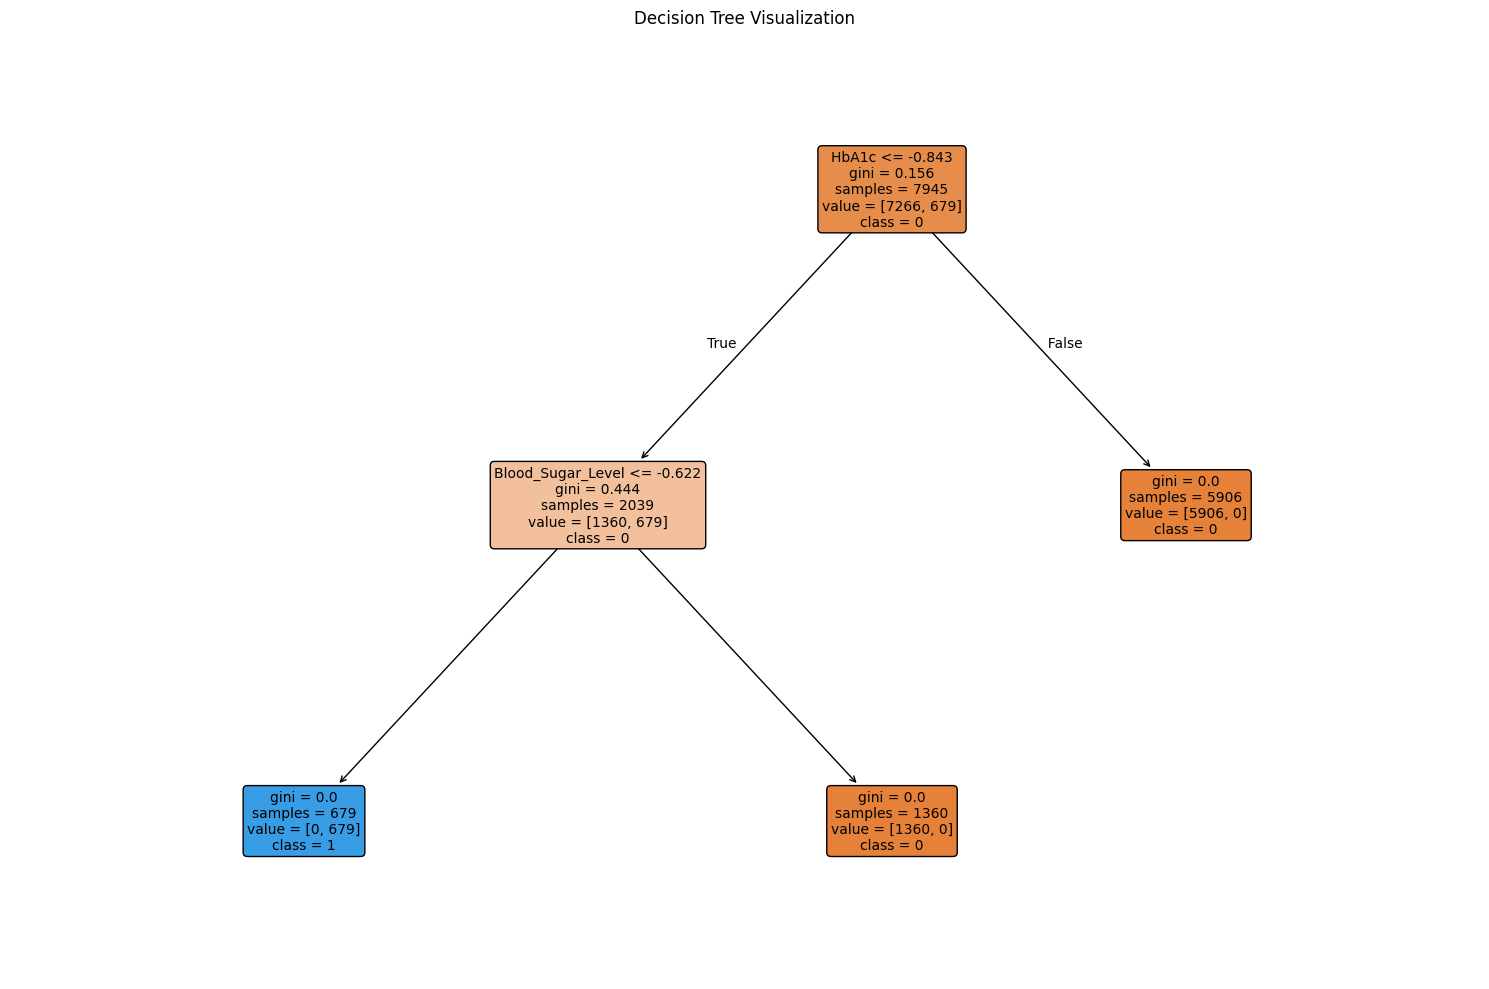

In [26]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

In [27]:

rf = DecisionTreeClassifier( random_state=42)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_,index=X.columns)

importances = importances.sort_values(ascending=False)

selected_columns = importances.sort_values(ascending=False).index[:8]
print("DecisionTree Selected Features:",selected_columns.tolist())
selected_features = importances.nlargest(8)
print("Decision Tree Selected Features:", selected_features.tolist())

DecisionTree Selected Features: ['Blood_Sugar_Level', 'HbA1c', 'Gender', 'Age', 'Creatinine', 'BMI', 'Urea', 'Cholesterol']
Decision Tree Selected Features: [0.729323471685561, 0.2706765283144391, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


In [28]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy,Precision,Recall,F1-Score
Method,,,,
Class Weight Balanced LogisticRegression,0.937091,0.577855,0.982353,0.727669
KNeighborsClassifier,0.961751,0.835714,0.688235,0.754839
GaussianNB,0.989935,1.000000,0.882353,0.937500
SVC,0.969804,0.848101,0.788235,0.817073
DecisionTreeClassifier,1.000000,1.000000,1.000000,1.000000


In [29]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[1789   28]
 [  35  135]]


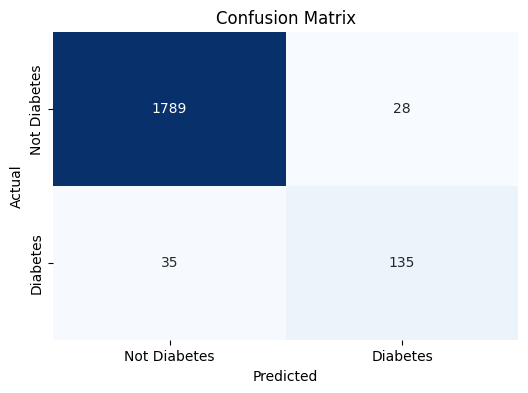


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.98      0.98      0.98      1817
      Stroke       0.83      0.79      0.81       170

    accuracy                           0.97      1987
   macro avg       0.90      0.89      0.90      1987
weighted avg       0.97      0.97      0.97      1987

ROC-AUC: 0.9901032730098093


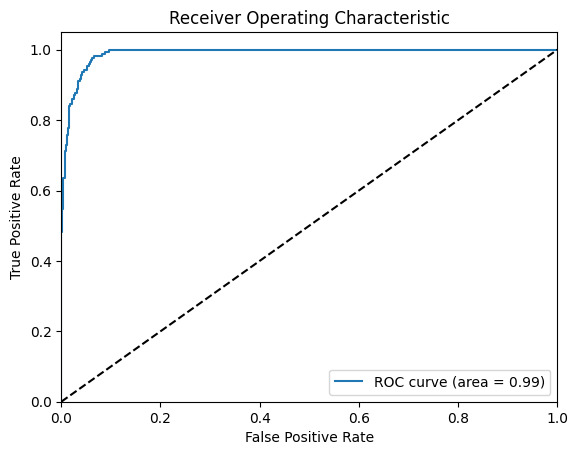

PR AUC: 0.9130440657396499


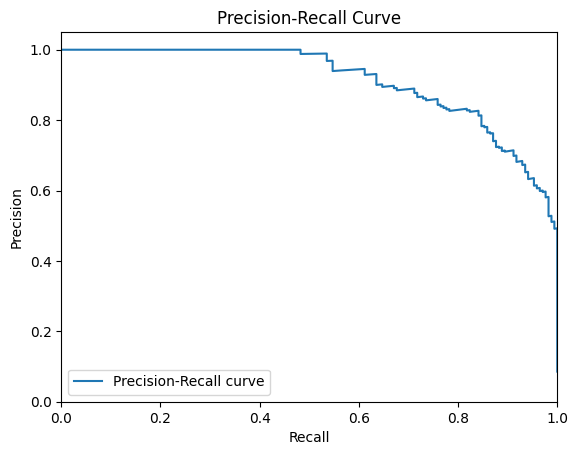

  8%|▊         | 1/13 [00:01<00:17,  1.46s/it]


Confusion Matrix:
 [[1788   29]
 [  52  118]]


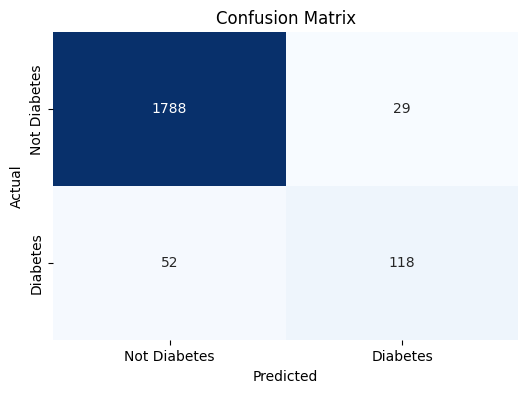


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.97      0.98      0.98      1817
      Stroke       0.80      0.69      0.74       170

    accuracy                           0.96      1987
   macro avg       0.89      0.84      0.86      1987
weighted avg       0.96      0.96      0.96      1987

ROC-AUC: 0.970371329599534


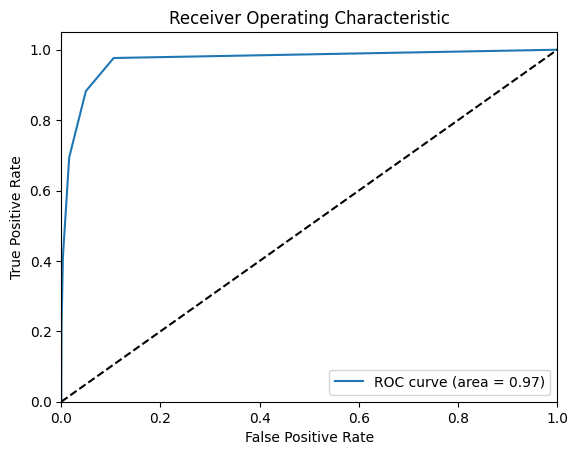

PR AUC: 0.7806640220521655


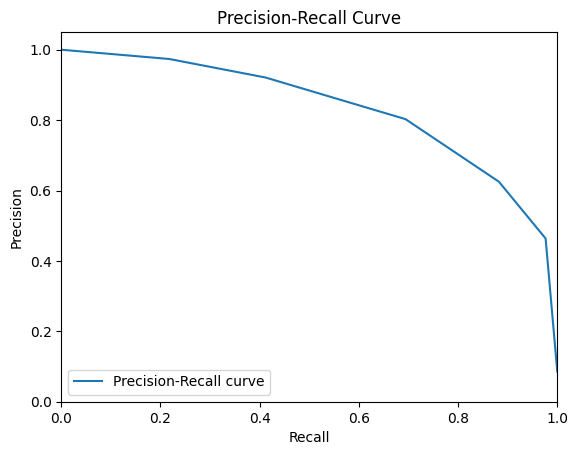

 15%|█▌        | 2/13 [00:04<00:27,  2.48s/it]


Confusion Matrix:
 [[1800   17]
 [  24  146]]


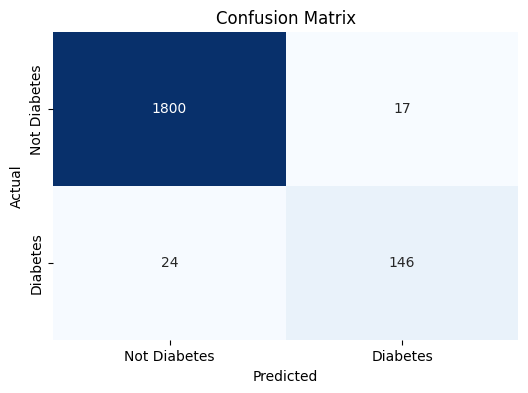


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      0.99      0.99      1817
      Stroke       0.90      0.86      0.88       170

    accuracy                           0.98      1987
   macro avg       0.94      0.92      0.93      1987
weighted avg       0.98      0.98      0.98      1987

ROC-AUC: 0.9953122470782478


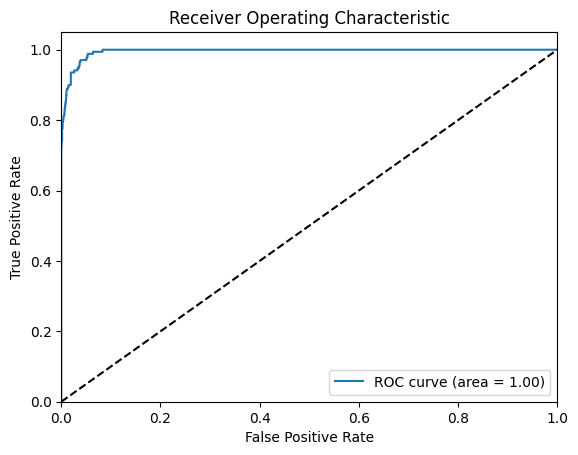

PR AUC: 0.9606466519859412


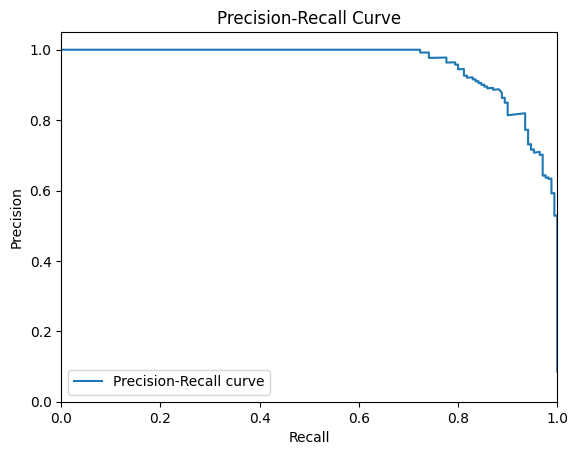

 23%|██▎       | 3/13 [00:10<00:40,  4.03s/it]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


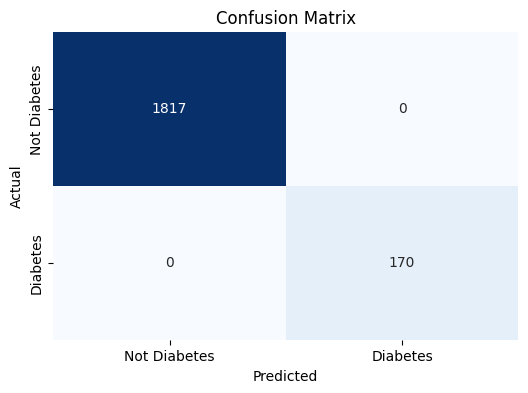


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


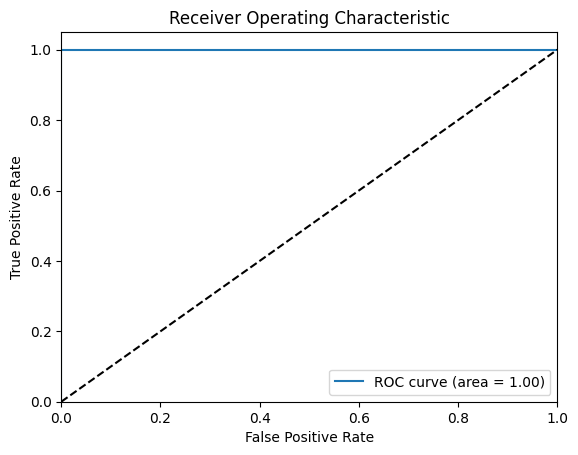

PR AUC: 1.0


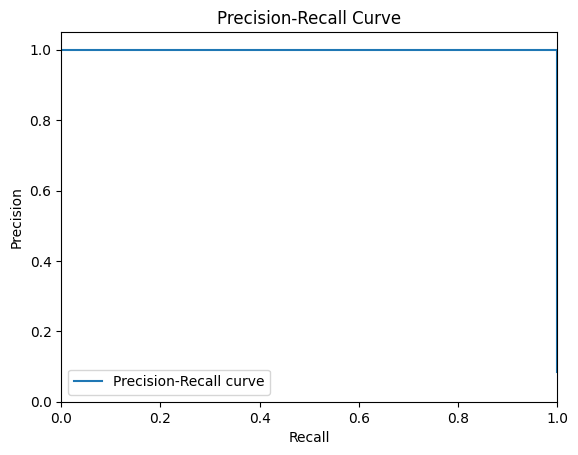

 31%|███       | 4/13 [00:11<00:25,  2.80s/it]


Confusion Matrix:
 [[1817    0]
 [  20  150]]


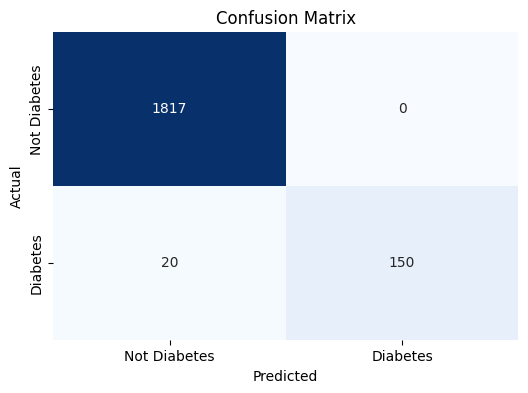


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      1.00      0.99      1817
      Stroke       1.00      0.88      0.94       170

    accuracy                           0.99      1987
   macro avg       0.99      0.94      0.97      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: 0.9992133121823303


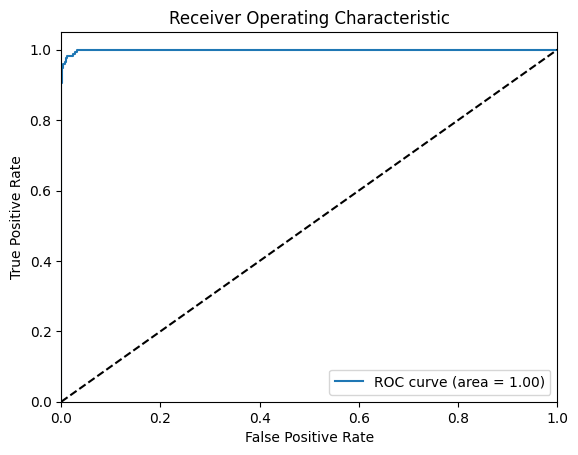

PR AUC: 0.9929167295194552


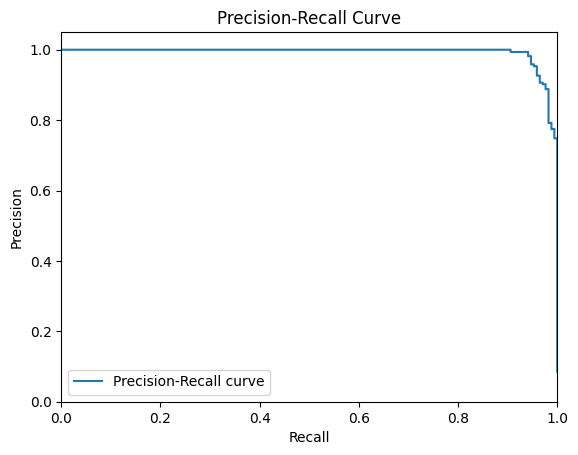

 38%|███▊      | 5/13 [00:12<00:16,  2.09s/it]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


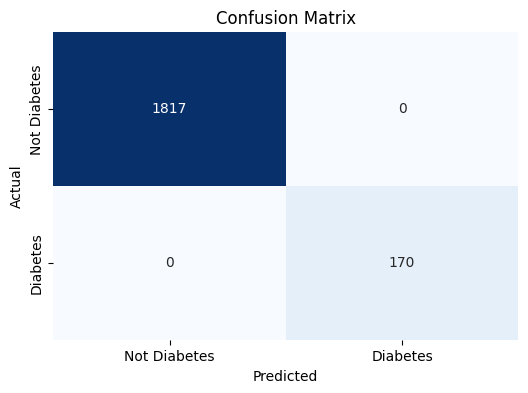


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


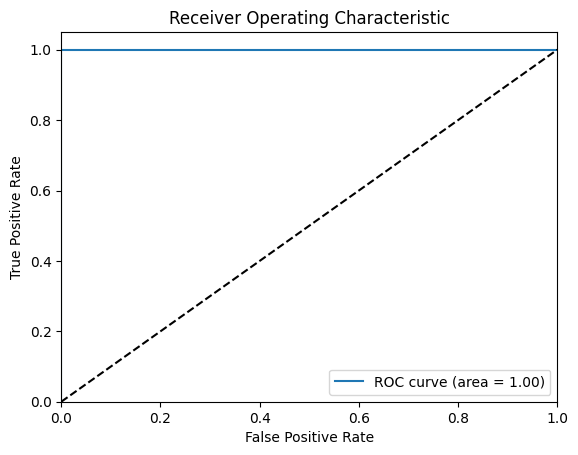

PR AUC: 0.9999999999999999


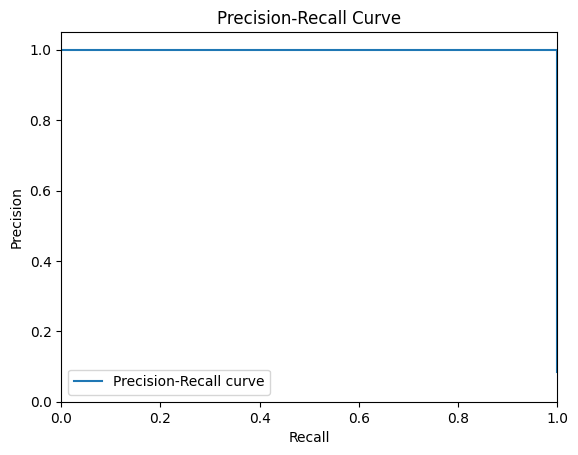

 46%|████▌     | 6/13 [00:14<00:16,  2.31s/it]


Confusion Matrix:
 [[1817    0]
 [  27  143]]


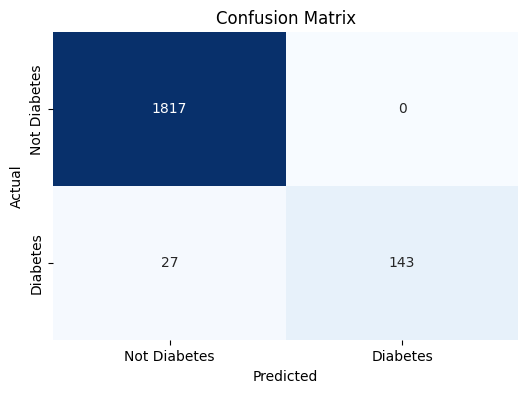


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      1.00      0.99      1817
      Stroke       1.00      0.84      0.91       170

    accuracy                           0.99      1987
   macro avg       0.99      0.92      0.95      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: 0.9994464048690472


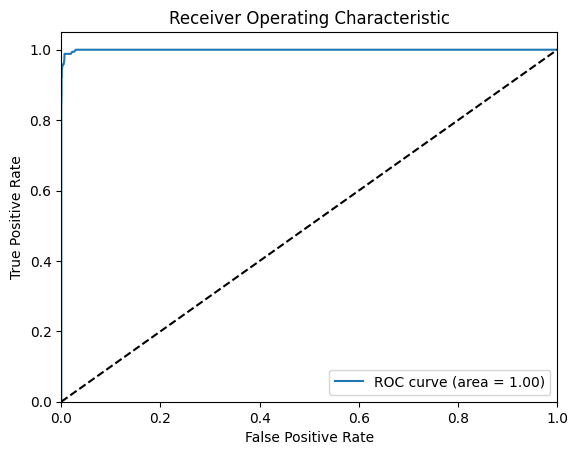

PR AUC: 0.9943108562917935


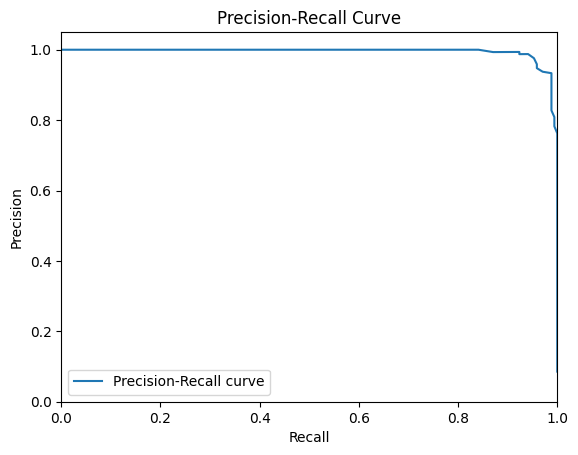

 54%|█████▍    | 7/13 [00:16<00:12,  2.11s/it]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


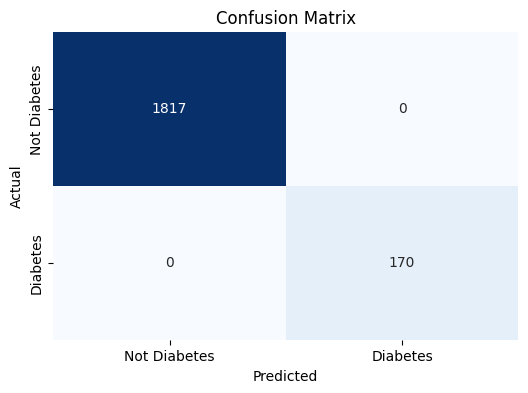


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


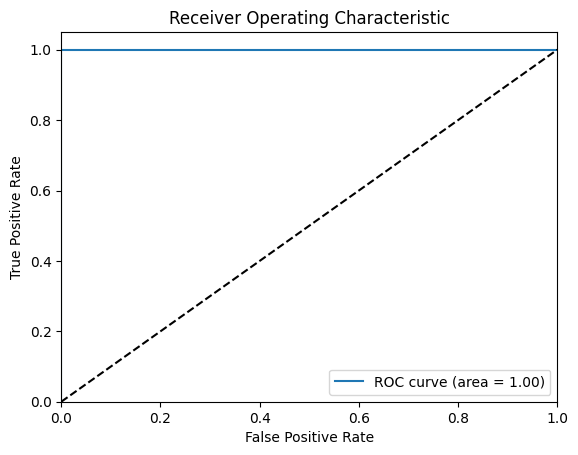

PR AUC: 1.0


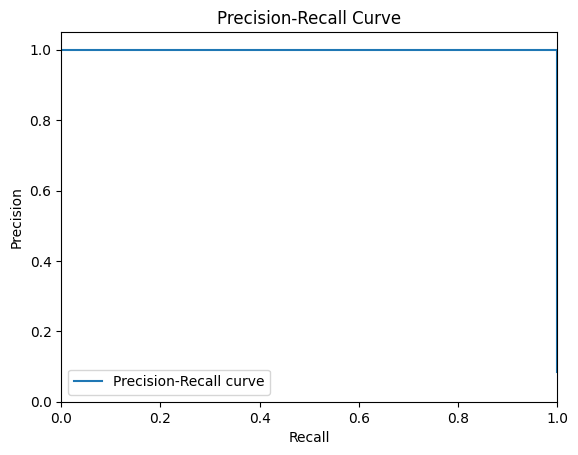

 62%|██████▏   | 8/13 [00:19<00:10,  2.20s/it]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


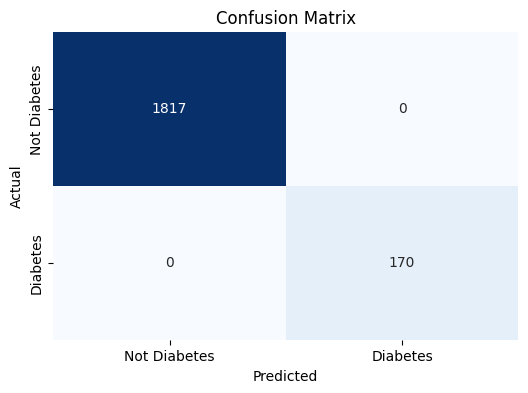


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


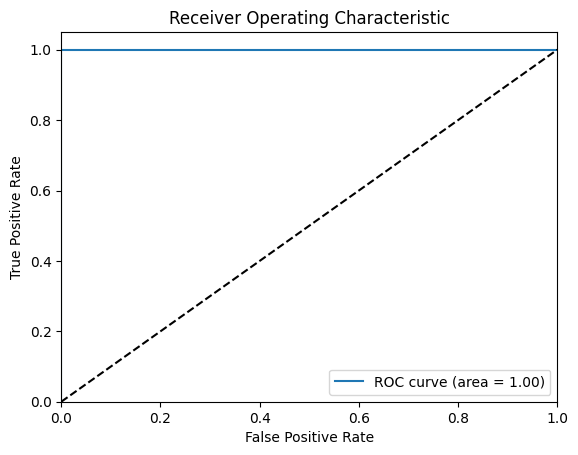

PR AUC: 1.0


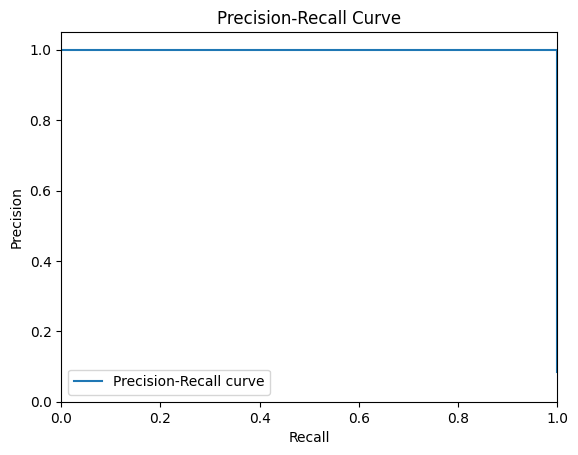

 69%|██████▉   | 9/13 [00:21<00:08,  2.21s/it]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


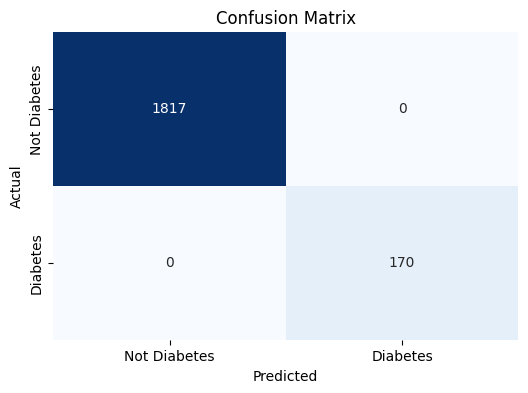


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


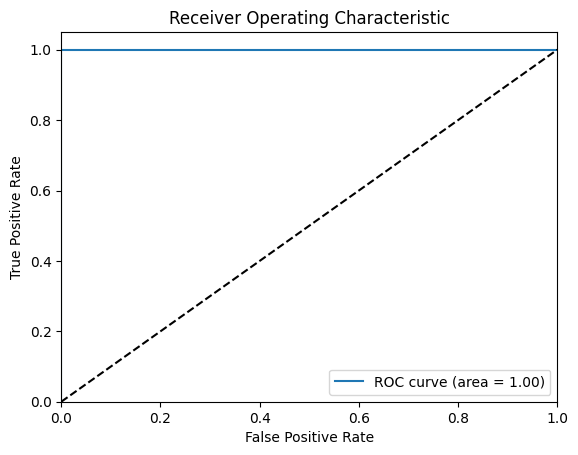

PR AUC: 1.0


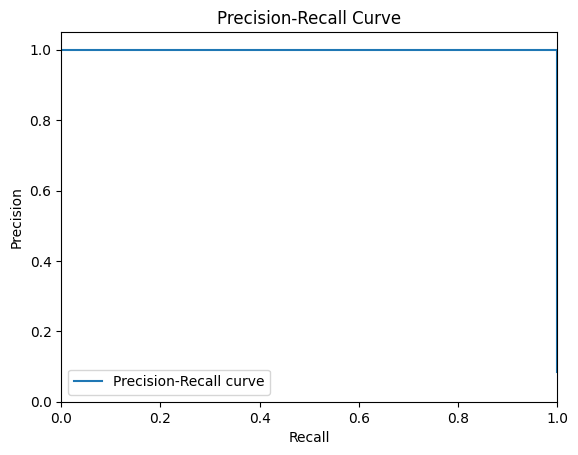

 77%|███████▋  | 10/13 [00:22<00:05,  1.95s/it]c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [13:15:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1817    0]
 [   0  170]]


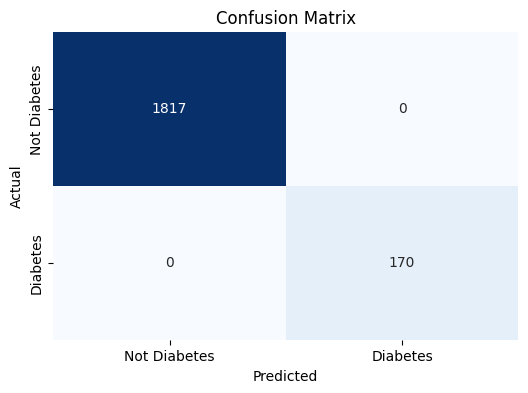


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


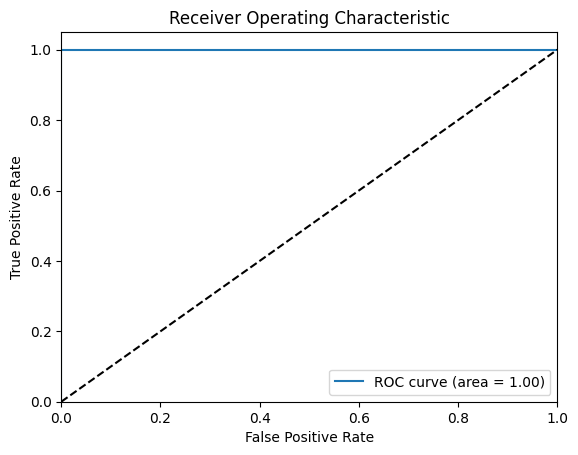

PR AUC: 1.0


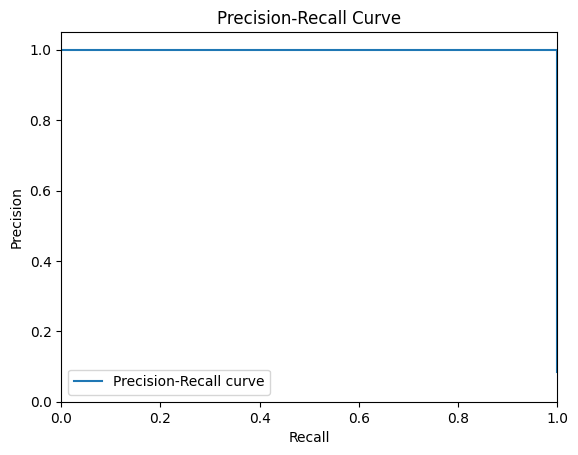

 85%|████████▍ | 11/13 [00:23<00:03,  1.69s/it]


Confusion Matrix:
 [[1817    0]
 [   0  170]]


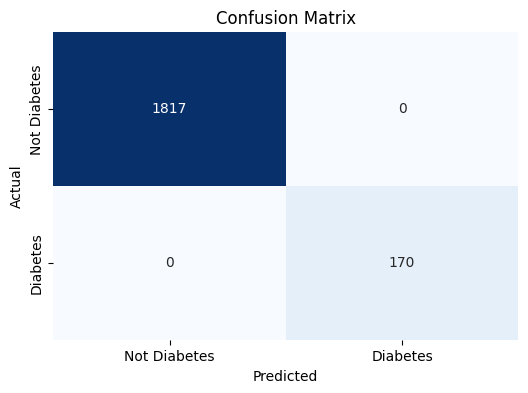


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


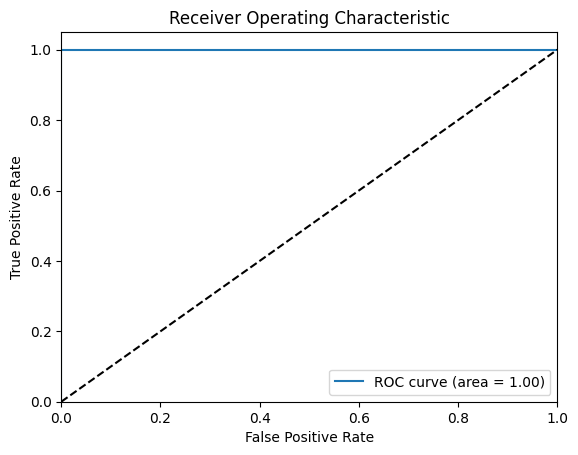

PR AUC: 0.9999999999999999


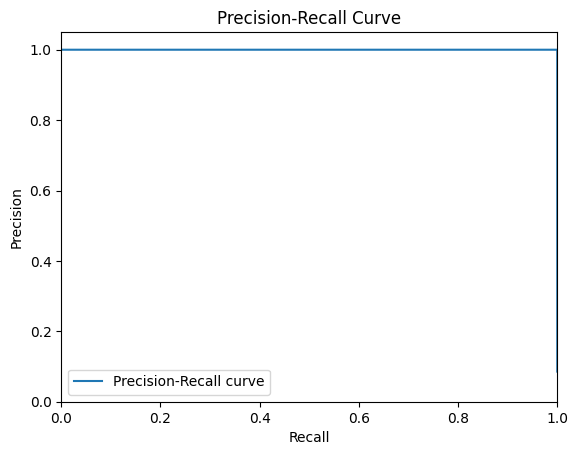

 92%|█████████▏| 12/13 [00:33<00:04,  4.22s/it]

[LightGBM] [Info] Number of positive: 679, number of negative: 7266
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001258 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 752
[LightGBM] [Info] Number of data points in the train set: 7945, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.085463 -> initscore=-2.370340
[LightGBM] [Info] Start training from score -2.370340
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

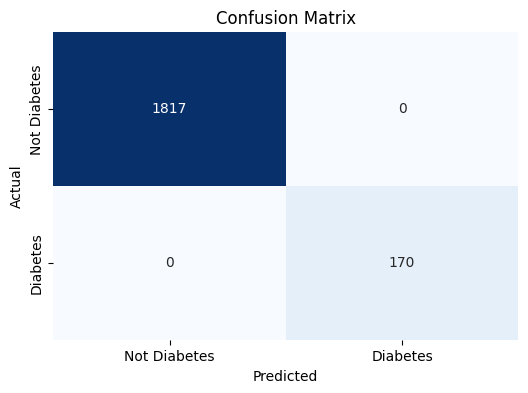


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


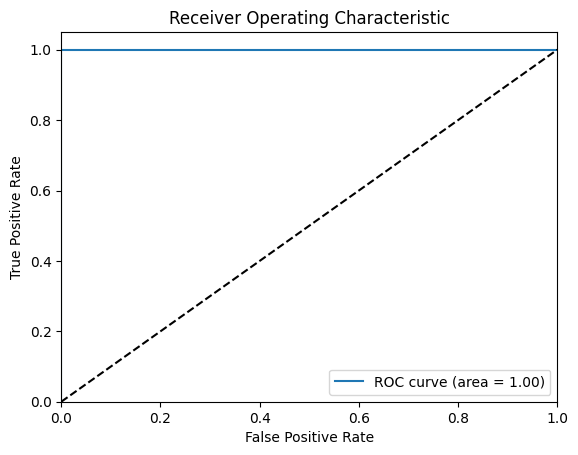

PR AUC: 1.0


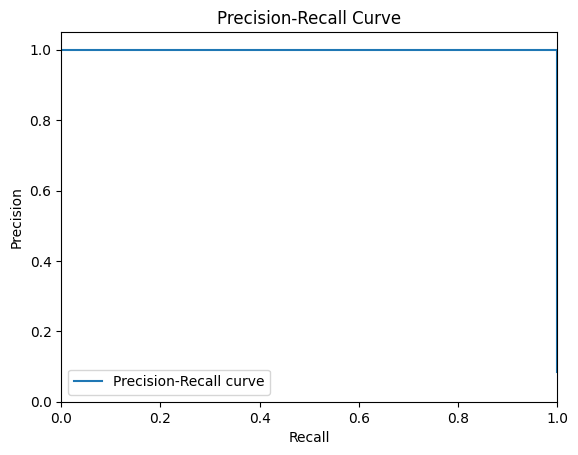

100%|██████████| 13/13 [00:35<00:00,  2.73s/it]


In [30]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Diabetes','Diabetes']
                ,yticklabels=['Not Diabetes','Diabetes'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [13:15:33] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1817    0]
 [   1  169]]


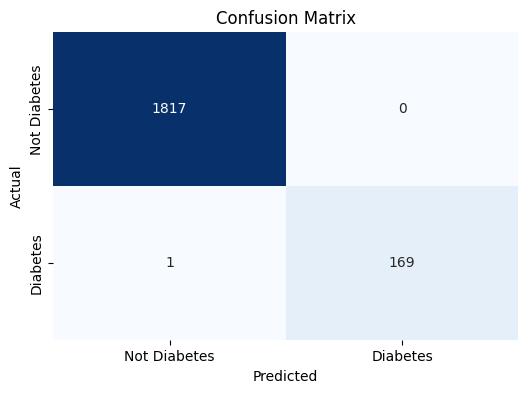


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      0.99      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


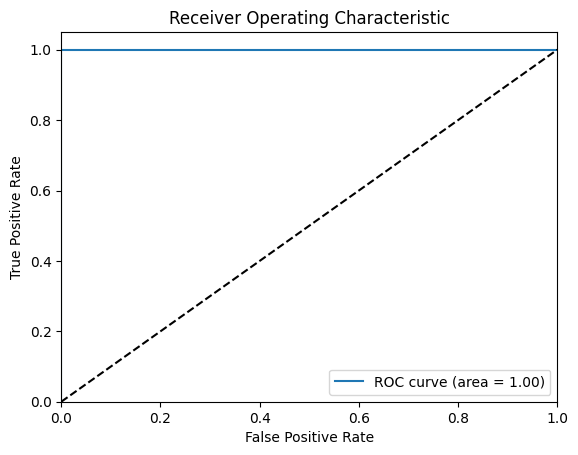

PR AUC: 0.9999999999999999


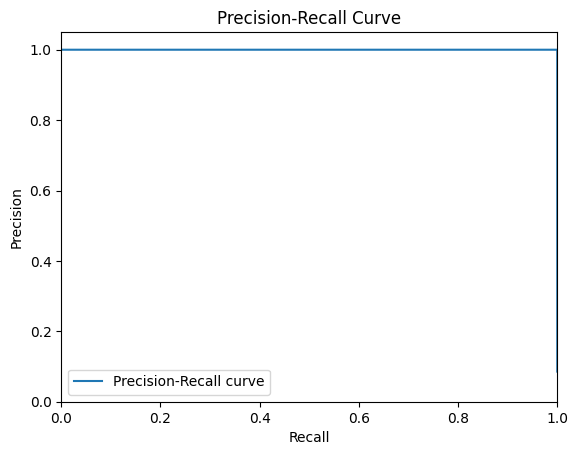

In [31]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Diabetes','Diabetes']
            ,yticklabels=['Not Diabetes','Diabetes'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [13:15:47] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[1817    0]
 [   0  170]]


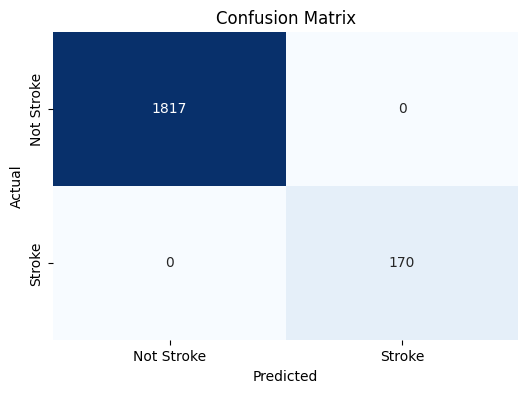


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00      1817
      Stroke       1.00      1.00      1.00       170

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


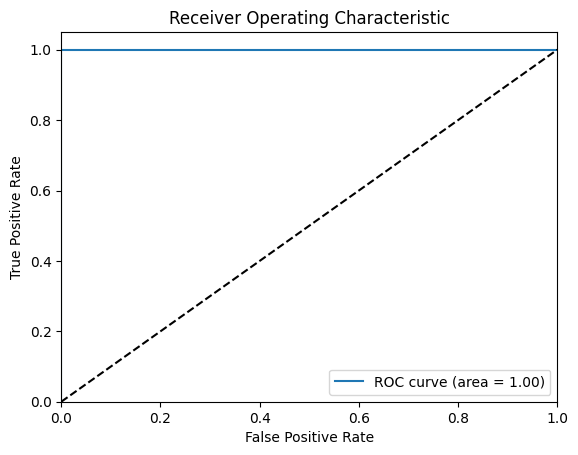

PR AUC: 1.0


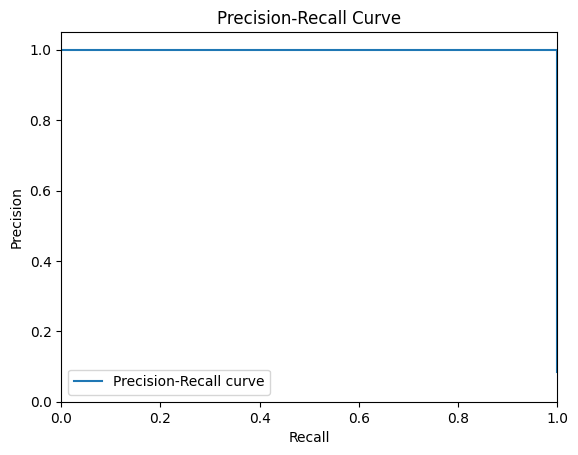

In [32]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),

        
    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [33]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
CatBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
XGBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Hist Gradient Boosting,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Gradient Boosting,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
AdaBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Stacking Classifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
LightGBM,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Voting Classifier,1.000000,0.999497,1.000000,1.000000,1.000000,0.994118,1.000000,0.997050,1.000000,0.997059,1.000000,1.000000


<Axes: >

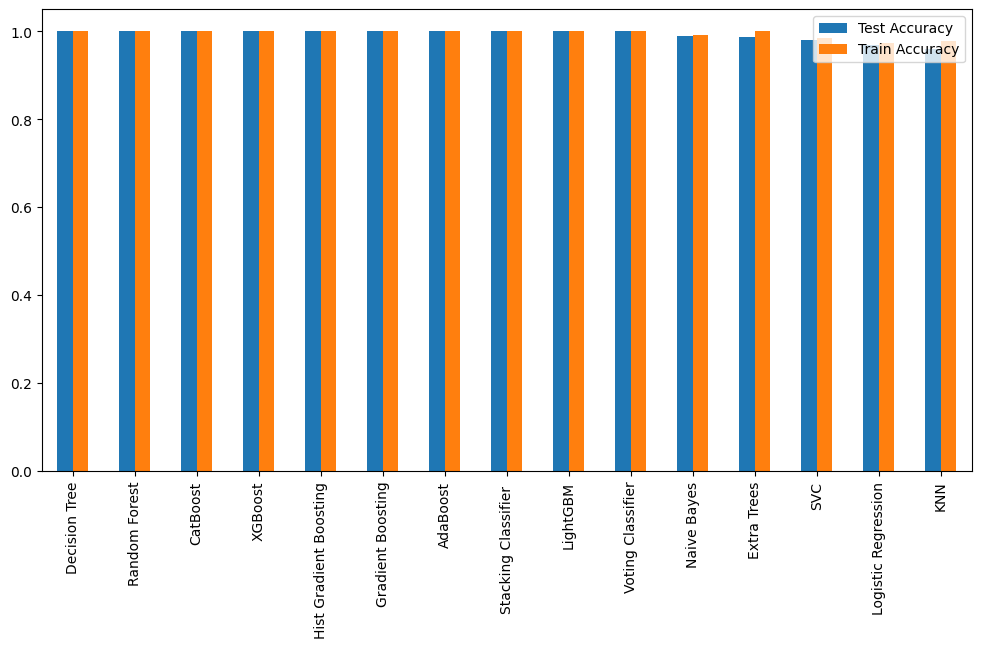

In [34]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

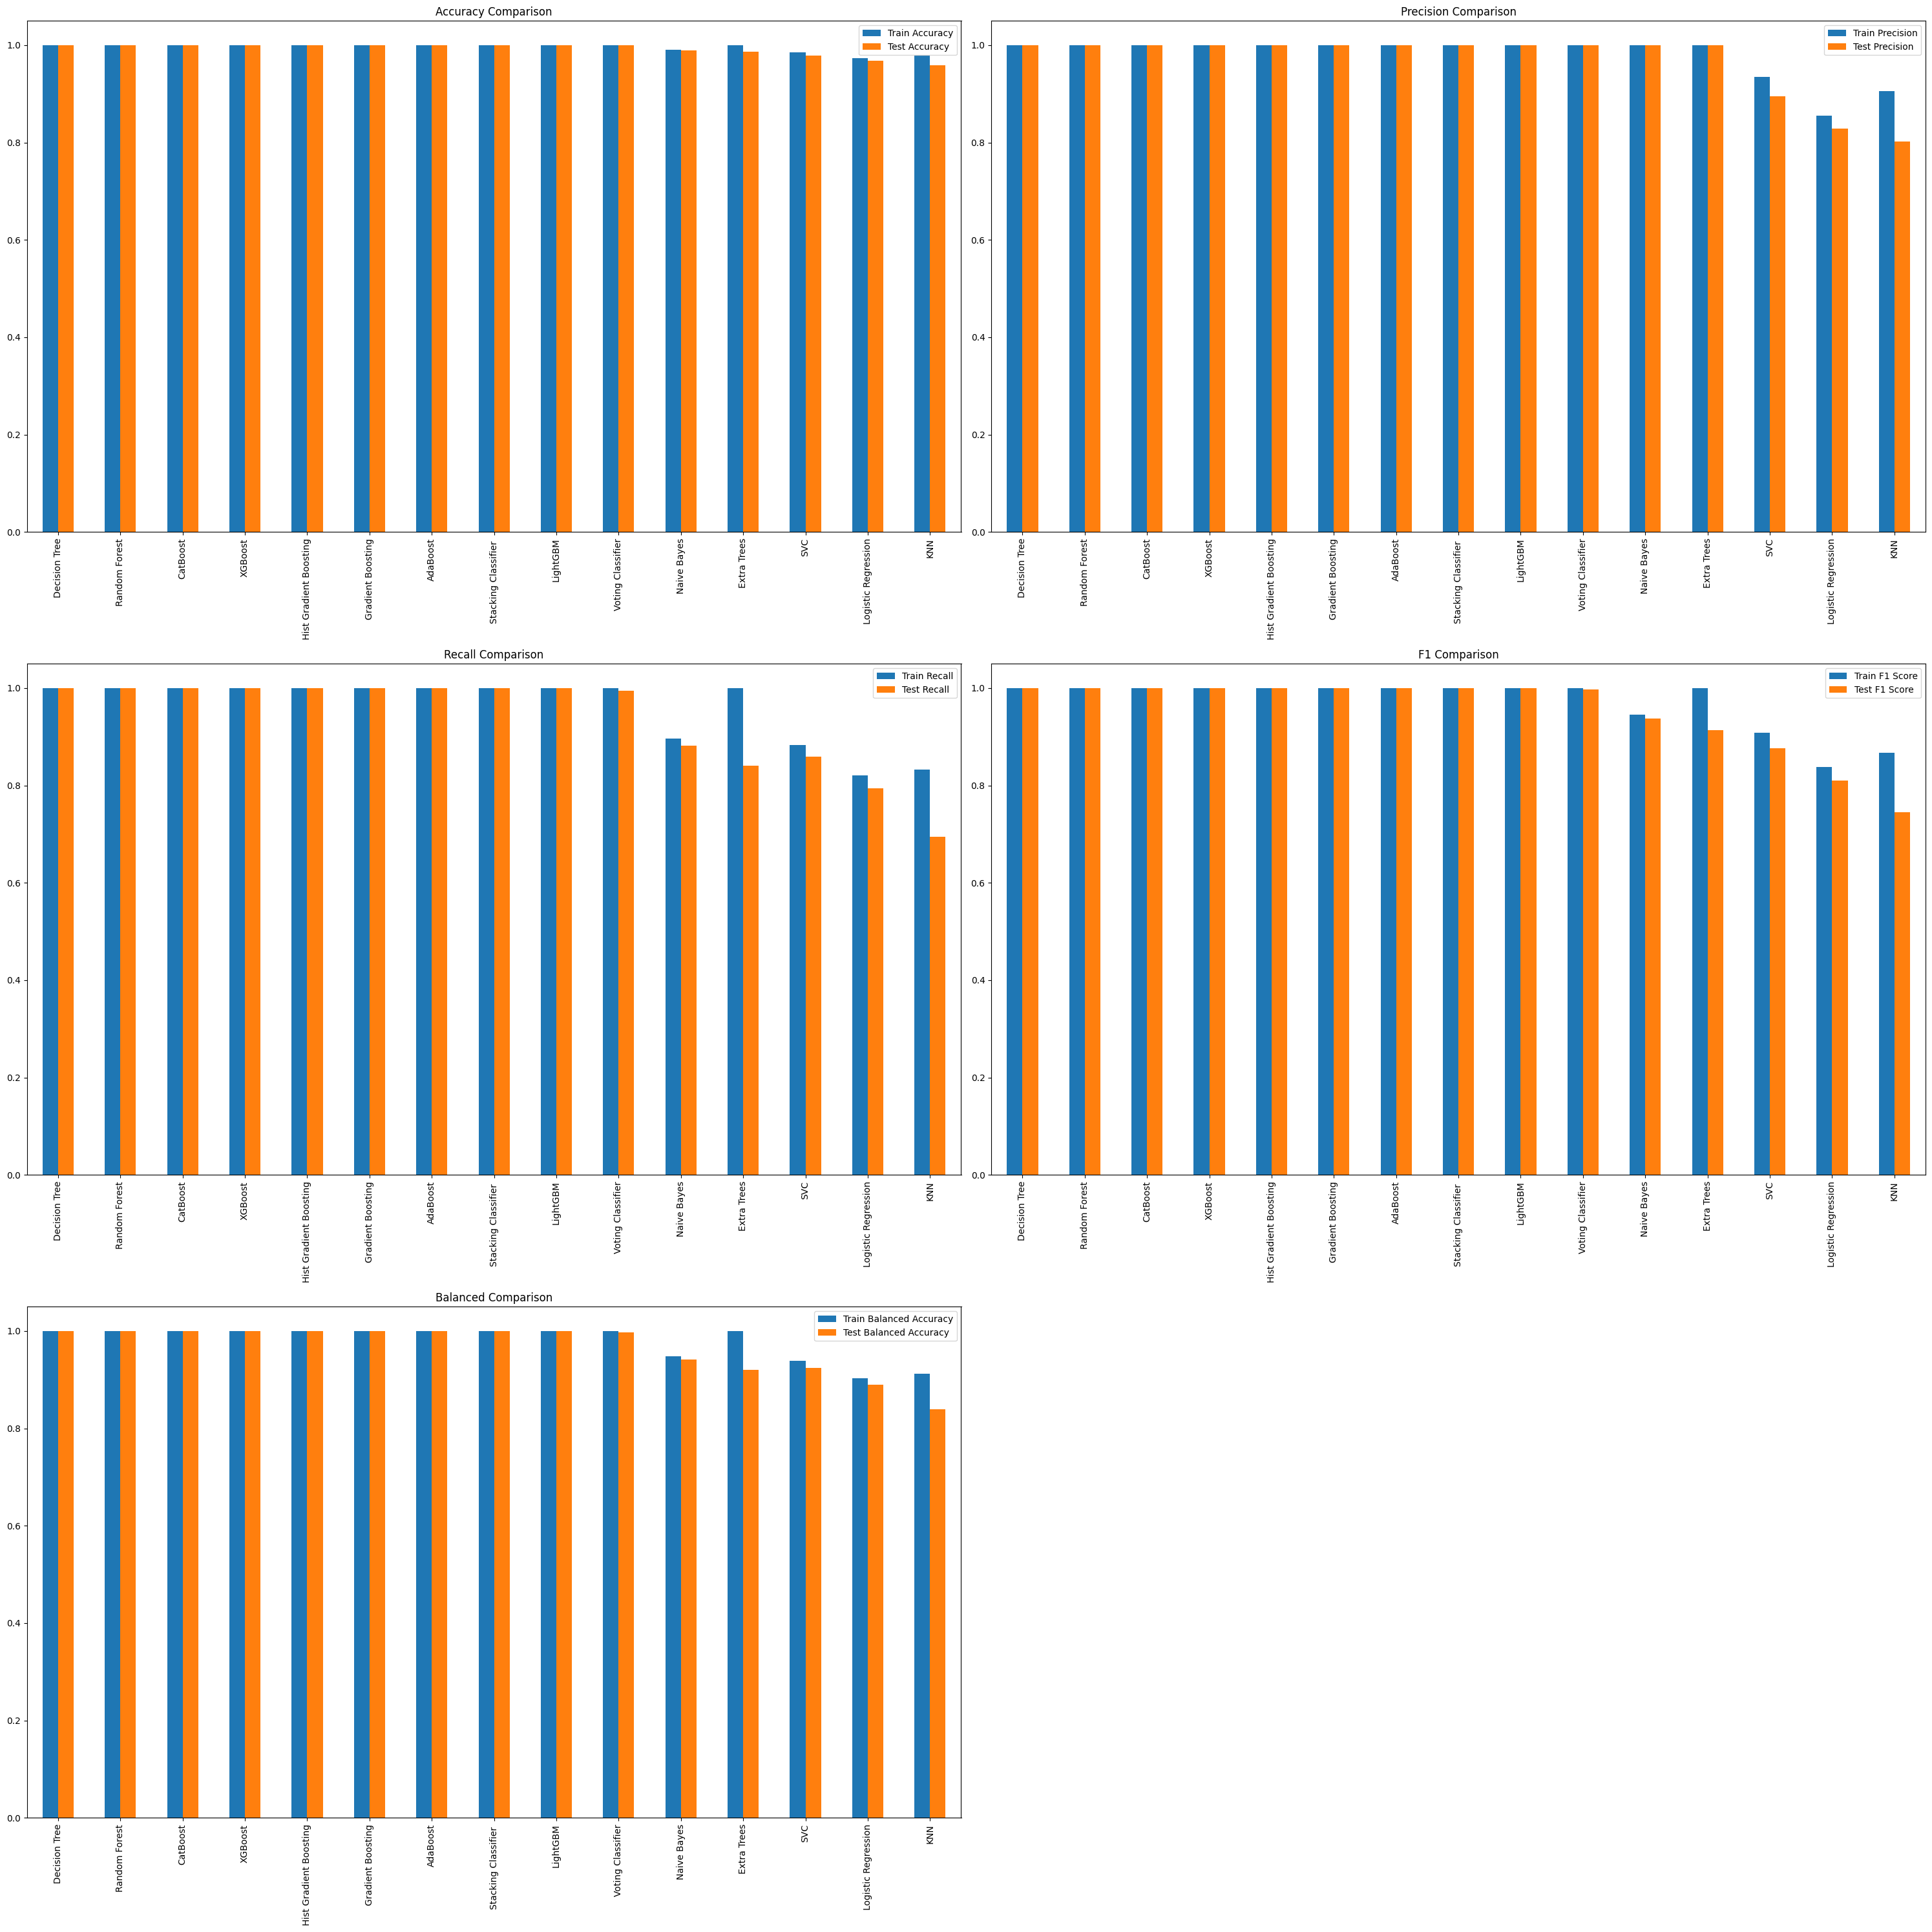

In [35]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)   
    results_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()